# 11 LSTM：把门、记忆和导数逐项拆开

序列第一步给出一个 ±0.8 的数，接下来 23 步都是小幅随机干扰，最后才要求读回最初的数。接收新输入时，需要保留有用的旧内容，也需要控制新内容写入多少。本课用这个延迟记忆任务理解 LSTM 的门。

## 1 用一个数控制保留比例

sigmoid 定义为 $\sigma(z)=1/(1+e^{-z})$，把实数 z 映射到 0 至 1。将它的输出乘在旧记忆上，就能连续调节保留比例。
先取旧记忆 $c_{t-1}=1$，遗忘门 $f_t=0.8$；保留下来的量是 $0.8\times1=0.8$。后面将让门值也根据输入与旧状态计算。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
torch.set_num_threads(1)
torch.manual_seed(11)
style()

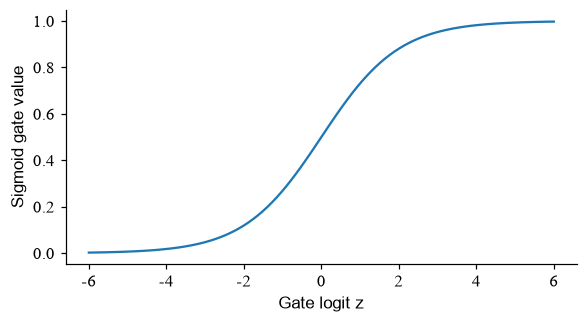

In [3]:
logits = np.linspace(-6, 6, 100)
gate_values = 1 / (1 + np.exp(-logits))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(logits, gate_values)
ax.set(xlabel='Gate logit z', ylabel='Sigmoid gate value')
show(fig)

### 练习 l01：从 logit 得到门

z=0 时门值是多少？旧记忆是 2，经过这个门剩多少？

In [4]:
ex_l01_z = 0.
ex_l01_gate = None  # TODO
ex_l01_kept = None  # TODO

In [5]:
# 填写上一格后，运行检查。
check('门值', ex_l01_gate, .5)
check('保留量', ex_l01_kept, 1.)

待填写：门值
待填写：保留量


<details>
<summary>提示</summary>

直接代入 sigmoid，再乘旧记忆。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l01_z = 0.
ex_l01_gate = 1 / (1 + np.exp(-ex_l01_z))
ex_l01_kept = ex_l01_gate * 2.
```

</details>

## 2 两个状态，四个受学习控制的量

x 是当前输入，c 保存内部记忆，h 提供当前读出，也用于下一步的门值计算。三个门 i、f、o 分别控制写入、保留、读出，候选 g 提供新内容。
先把保留项与写入项相加得到 c，再从 c 计算 h。向量中每个分量都做这样的更新；各门有自己的权重与偏置，下面用 z 表示它们各自的仿射结果：
$$i_t=\sigma(z_i),\quad f_t=\sigma(z_f),\quad g_t=\tanh(z_g),\quad o_t=\sigma(z_o),$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$
每个 $z_q=x_tW_{xq}+h_{t-1}W_{hq}+b_q$。符号 $\odot$ 表示对应分量相乘。

In [6]:
f, i, g, o = .8, .2, .5, .7
c_previous = 1.
retained = f * c_previous
written = i * g
c_next = retained + written
h_next = o * np.tanh(c_next)
print('retained / written / cell / hidden:', retained, written, c_next, h_next)

retained / written / cell / hidden: 0.8 0.1 0.9 0.5014085091393171


旧内容留下 .8，新内容写入 .2×.5=.1，合成的新记忆 c 为 .9。读出先取 tanh(.9)，再乘输出门 .7。c 与 h 都传到下一时刻：c 沿记忆通路继续保留和更新，h 参与下一步四个门的计算。

### 练习 l02：一步记忆更新

f=.9，i=.1，g=−.5，o=.8，旧 c=2，求新 c 和新 h。

In [7]:
ex_l02_c = None  # TODO: 保留项加写入项
ex_l02_h = None  # TODO: 读出门乘 tanh
ex_l02_previous = 2.

In [8]:
# 填写上一格后，运行检查。
check('新记忆', ex_l02_c, 1.75)
check('新隐藏状态', ex_l02_h, .8*np.tanh(1.75))

待填写：新记忆
待填写：新隐藏状态


<details>
<summary>提示</summary>

c=.9×2+.1×(−.5)。随后计算 .8×tanh(c)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l02_previous = 2.
ex_l02_c = .9 * ex_l02_previous + .1 * (-.5)
ex_l02_h = .8 * np.tanh(ex_l02_c)
```

</details>

## 3 沿记忆通路回传，再把门的支路接上

新记忆由四个量共同决定。沿每一条输入边单独看：旧记忆先乘 f，遗忘门先乘旧记忆，输入门与候选值互相相乘。因此固定当前门值时，直接记忆通路的局部导数为
$$\frac{\partial c_t}{\partial c_{t-1}}\bigg|_{i,f,g}=f_t,\quad
\frac{\partial c_t}{\partial f_t}=c_{t-1},\quad
\frac{\partial c_t}{\partial i_t}=g_t,\quad
\frac{\partial c_t}{\partial g_t}=i_t.$$
读出还有 $\partial h_t/\partial c_t=o_t[1-\tanh^2(c_t)]$。末端损失沿读出回到 c 后，会分别乘上以上局部导数，继续传给旧记忆和各个门。

把多个时刻接起来，直接记忆通路每经过一步就乘一次 f，得到 $\prod_t f_t$。同时，旧 h 会改变下一步各门，形成 $h_{t-1}\to z_q\to$ 各门的支路。完整 BPTT 会把这些支路的贡献也传回来，在同一个旧状态处相加。

In [9]:
c0 = torch.tensor(1., dtype=torch.float64, requires_grad=True)
f0 = torch.tensor(.8, dtype=torch.float64, requires_grad=True)
i0 = torch.tensor(.2, dtype=torch.float64, requires_grad=True)
g0 = torch.tensor(.5, dtype=torch.float64, requires_grad=True)
c1 = f0*c0 + i0*g0
direct_grads = torch.autograd.grad(c1, (c0, f0, i0, g0))
print('dc/d(c_previous,f,i,g):', [v.item() for v in direct_grads])
check('四条局部导数', torch.stack(direct_grads), [.8, 1., .5, .2])

dc/d(c_previous,f,i,g): [0.8, 1.0, 0.5, 0.2]
通过：四条局部导数


### 练习 l03：将读出导数继续传回旧记忆

门值固定为 f=.8、i=.2、g=.5、o=.7，旧 c=1。用链式法则求 dh_new/dc_previous。

In [10]:
ex_l03_c = .8 * 1. + .2 * .5
ex_l03_gradient = None  # TODO
ex_l03_f = .8

In [11]:
# 填写上一格后，运行检查。
check('读出到旧记忆的导数', ex_l03_gradient, .7*(1-np.tanh(.9)**2)*.8)

待填写：读出到旧记忆的导数


<details>
<summary>提示</summary>

先通过 o*tanh(c)，再通过直接通路的 f。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l03_c = .8 * 1. + .2 * .5
ex_l03_f = .8
ex_l03_gradient = .7 * (1-np.tanh(ex_l03_c)**2) * ex_l03_f
```

</details>

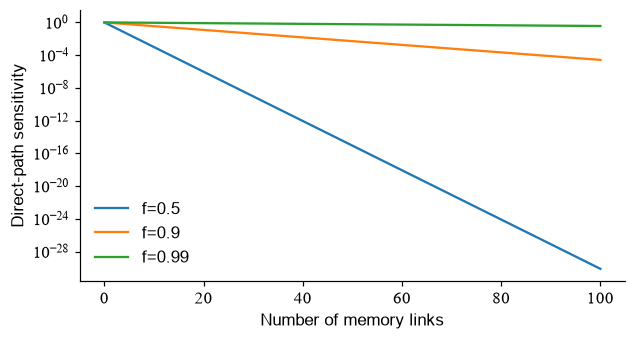

In [12]:
horizon = np.arange(101)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for forget in [.5, .9, .99]:
    ax.semilogy(horizon, forget**horizon, label=f'f={forget}')
ax.set(xlabel='Number of memory links', ylabel='Direct-path sensitivity')
ax.legend(frameon=False)
show(fig)

### 练习 l04：把 logit 的导数也算进去

i=sigmoid(z)，c=.8×1+i×.5；取 i=.2。计算 dc/dz。

In [13]:
ex_l04_i = .2
ex_l04_gradient = None  # TODO: 候选值 × sigmoid 导数
ex_l04_candidate = .5

In [14]:
# 填写上一格后，运行检查。
check('门 logit 的梯度', ex_l04_gradient, .08)

待填写：门 logit 的梯度


<details>
<summary>提示</summary>

sigmoid 的导数是 i(1−i)，并乘上 dc/di=g。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l04_i = .2
ex_l04_candidate = .5
ex_l04_gradient = ex_l04_candidate * ex_l04_i * (1-ex_l04_i)
```

</details>

## 4 把四次仿射合成一个张量

四个门使用同一份 x 和旧 h，各有一组仿射参数。把四组参数并排存放，就能用两次矩阵乘法一次算出四组 z。

F 为输入特征数，H 为隐藏宽度。输入是 `(B,F)`，旧 h、c 都是 `(B,H)`。一个 `Linear(F,4H)` 与一个 `Linear(H,4H)` 相加，得到 `(B,4H)`；沿最后一维分成 i、f、g、o 四块，每块 `(B,H)`。这个顺序与 PyTorch LSTM 一致。

In [15]:
packed = torch.arange(12.).reshape(1, 12)
pieces = packed.chunk(4, dim=-1)
for name, piece in zip(['i', 'f', 'g', 'o'], pieces):
    print(name, piece)

i tensor([[0., 1., 2.]])
f tensor([[3., 4., 5.]])
g tensor([[6., 7., 8.]])
o tensor([[ 9., 10., 11.]])


### 练习 l05：找到遗忘门那一块

H=2，打包向量为 [0,1,2,3,4,5,6,7]。取 f 的两个 logit。

In [16]:
ex_l05_packed = torch.arange(8.).reshape(1, 8)
ex_l05_forget = None  # TODO
ex_l05_H = 2

In [17]:
# 填写上一格后，运行检查。
check('遗忘门 logit', ex_l05_forget, [[2.,3.]])

待填写：遗忘门 logit


<details>
<summary>提示</summary>

i 占前 H 列，f 占第 H 到 2H 列。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l05_packed = torch.arange(8.).reshape(1, 8)
ex_l05_H = 2
ex_l05_forget = ex_l05_packed[:, ex_l05_H:2*ex_l05_H]
```

</details>

下面把遗忘门的输入偏置初始化为 2，其余偏置为 0。输入和旧 h 都为零时，遗忘门由 sigmoid(2) 决定，开始时倾向保留较多旧记忆。实际门值还会受到输入、旧状态和权重的共同影响；偏置也随训练更新。

In [18]:
class ManualLSTMCell(nn.Module):
    def __init__(self, features, hidden):
        super().__init__()
        self.hidden = hidden
        self.i2h = nn.Linear(features, 4*hidden)
        self.h2h = nn.Linear(hidden, 4*hidden)
        with torch.no_grad():
            self.i2h.bias.zero_(); self.h2h.bias.zero_()
            self.i2h.bias[hidden:2*hidden].fill_(2.)
    def forward(self, x, h, c):
        zi, zf, zg, zo = (self.i2h(x)+self.h2h(h)).chunk(4, dim=-1)
        i, f = torch.sigmoid(zi), torch.sigmoid(zf)
        g, o = torch.tanh(zg), torch.sigmoid(zo)
        c = f*c + i*g
        h = o*torch.tanh(c)
        return h, c, torch.stack((i, f, g, o), dim=1)

现在将同一组参数交给两种实现，检查刚才的公式是否逐步对得上。用 float64 把手写单元的两组权重、两组偏置原样复制给 nn.LSTM；两组偏置在前向中相加。给它们完全相同的四步输入，再比较所有时刻的 h 与最后的 c。首次出现差异的时刻，可以帮助定位门顺序或状态更新中的问题。

In [19]:
manual = ManualLSTMCell(2, 3).double()
builtin = nn.LSTM(2, 3, batch_first=True).double()
with torch.no_grad():
    builtin.weight_ih_l0.copy_(manual.i2h.weight)
    builtin.weight_hh_l0.copy_(manual.h2h.weight)
    builtin.bias_ih_l0.copy_(manual.i2h.bias)
    builtin.bias_hh_l0.copy_(manual.h2h.bias)
alignment_X = torch.randn(2, 4, 2, dtype=torch.float64)

In [20]:
h, c = torch.zeros(2, 3, dtype=torch.float64), torch.zeros(2, 3, dtype=torch.float64)
manual_outputs = []
for t in range(4):
    h, c, gates = manual(alignment_X[:, t], h, c)
    manual_outputs.append(h)
reference_output, (reference_h, reference_c) = builtin(alignment_X)
check('所有时刻的 h', torch.stack(manual_outputs, dim=1), reference_output, atol=1e-10)
check('最终 c', c, reference_c[0], atol=1e-10)

通过：所有时刻的 h


通过：最终 c


### 练习 l06：两组偏置怎样进入同一个门

输入仿射给出 [.1,.2,.3,.4]，状态仿射给出 [.5,.6,.7,.8]。H=1，取合并后 f 的 logit 与门值。

In [21]:
ex_l06_input = np.array([.1,.2,.3,.4])
ex_l06_state = np.array([.5,.6,.7,.8])
ex_l06_zf = None  # TODO
ex_l06_f = None  # TODO

In [22]:
# 填写上一格后，运行检查。
check('f 的 logit', ex_l06_zf, .8)
check('f 门值', ex_l06_f, 1/(1+np.exp(-.8)))

待填写：f 的 logit
待填写：f 门值


<details>
<summary>提示</summary>

两数组先相加，f 位于索引 1，再计算 sigmoid。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l06_input = np.array([.1,.2,.3,.4])
ex_l06_state = np.array([.5,.6,.7,.8])
ex_l06_zf = (ex_l06_input+ex_l06_state)[1]
ex_l06_f = 1/(1+np.exp(-ex_l06_zf))
```

</details>

## 5 让记忆跨过 23 步干扰

回到开头的任务。每条序列长 24，第一时刻输入随机的 ±0.8，第二通道同时给出“写入标记”1；后续时刻第一通道只有独立小噪声，标记为 0。标记告诉网络哪一步的内容需要记住，目标是在最后一步读回那个数。

训练和测试使用独立生成的整条序列。平方误差只从最后读出进入计算图；第一步的输入和门要得到学习信号，梯度就需要经过中间 23 次状态更新。

In [23]:
generator = torch.Generator().manual_seed(111)
memory_X = .15*torch.randn(384, 24, 2, generator=generator)
memory_target = (torch.randint(0, 2, (384, 1), generator=generator)*2-1).float()*.8
memory_X[:, :, 1] = 0.
memory_X[:, 0, 0] = memory_target[:, 0]
memory_X[:, 0, 1] = 1.
memory_train_X, memory_test_X = memory_X[:288], memory_X[288:]
memory_train_Y, memory_test_Y = memory_target[:288], memory_target[288:]

In [24]:
class MemoryLSTM(nn.Module):
    def __init__(self, hidden=12):
        super().__init__()
        self.cell = ManualLSTMCell(2, hidden)
        self.readout = nn.Linear(hidden, 1)
    def forward(self, X):
        h = X.new_zeros(X.shape[0], self.cell.hidden)
        c = torch.zeros_like(h)
        gate_trace, cell_trace = [], []
        for t in range(X.shape[1]):
            h, c, gates = self.cell(X[:, t], h, c)
            gate_trace.append(gates); cell_trace.append(c)
        return self.readout(h), torch.stack(gate_trace, dim=1), torch.stack(cell_trace, dim=1)

In [25]:
torch.manual_seed(112)
memory_model = MemoryLSTM()
optimizer = torch.optim.Adam(memory_model.parameters(), lr=.02)
memory_losses = []
for epoch in range(240):
    optimizer.zero_grad()
    output, _, _ = memory_model(memory_train_X)
    loss = (output-memory_train_Y).square().mean()
    loss.backward(); optimizer.step()
    memory_losses.append(loss.item())

In [26]:
with torch.no_grad():
    memory_output, gate_trace, cell_trace = memory_model(memory_test_X)
print('test MSE:', (memory_output-memory_test_Y).square().mean().item())
print('zero-prediction MSE:', memory_test_Y.square().mean().item())
print('target / prediction:', torch.cat([memory_test_Y[:6], memory_output[:6]], dim=1))
trace_unit = int(cell_trace[0].var(dim=0).argmax())

test MSE: 8.136107680911664e-06
zero-prediction MSE: 0.64000004529953
target / prediction: tensor([[-0.8000, -0.8022],
        [-0.8000, -0.7996],
        [-0.8000, -0.8002],
        [-0.8000, -0.8001],
        [-0.8000, -0.7984],
        [ 0.8000,  0.7977]])


先看前六条测试序列的目标与预测，再选测试序列 0 中随时间变化最大的记忆分量。下图始终画这个分量的 i、f、o、c 和候选 g。逐时刻对照 f×旧 c 与 i×g，就能将记忆的变化接回刚才的一步公式。候选 g 的范围是 −1 至 1；c 由保留项和写入项累加，可以超出这个范围，读出 h 再经过 tanh。

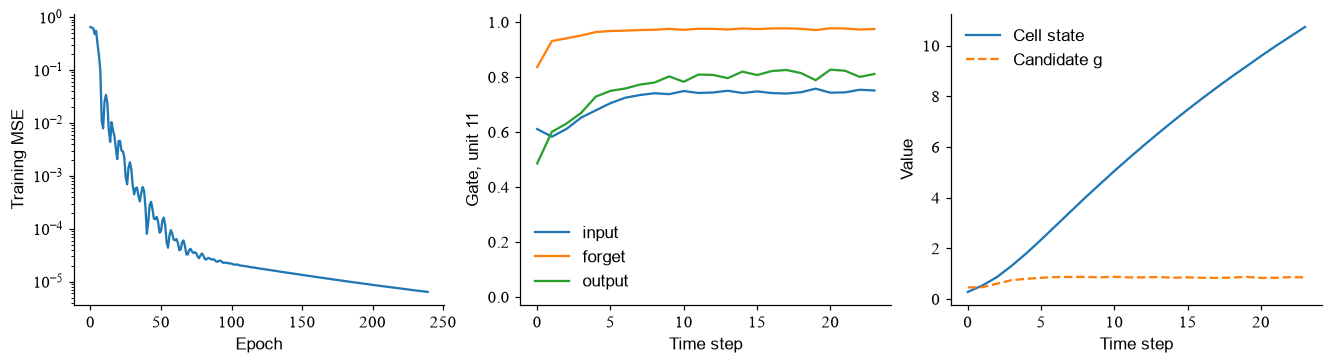

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout='constrained')
axes[0].semilogy(memory_losses); axes[0].set(xlabel='Epoch', ylabel='Training MSE')
for gate_index, name in [(0,'input'), (1,'forget'), (3,'output')]:
    axes[1].plot(gate_trace[0, :, gate_index, trace_unit], label=name)
axes[1].set(xlabel='Time step', ylabel=f'Gate, unit {trace_unit}', ylim=(-.03,1.03))
axes[1].legend(frameon=False)
axes[2].plot(cell_trace[0, :, trace_unit], label='Cell state')
axes[2].plot(gate_trace[0, :, 2, trace_unit], '--', label='Candidate g')
axes[2].set(xlabel='Time step', ylabel='Value'); axes[2].legend(frameon=False)
show(fig)

如果一段时间里候选 g 持续同号、输入门 i 持续开启，写入项就可能累积；遗忘门 f 接近 1 时，旧内容也保留得较多。读门值时，把相邻两步 c 的数值一起看，判断这一段变化主要来自保留还是写入。

把延迟从 24 改为 48，其余设置保留，时间链就增加了 24 次状态更新。记录测试误差与第一时刻输入梯度，比较记忆能否跨过更长的干扰段。另做一次实验，将遗忘门初始偏置从 2 改为 0；对照直接通路乘积与训练后的实际门值，观察初始化怎样影响学习过程。

权重布局可继续查 [PyTorch LSTM 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html)。把自写单元的 g、o 块对调，运行逐时刻核对，定位首次偏离的状态。

## 带着问题读原文

[Hochreiter 与 Schmidhuber：Long Short-Term Memory（1997）](https://ml.jku.at/publications/older/2604.pdf)

在原文图中找到线性记忆通路、输入门与输出门，画出与本课公式的对应。继续阅读 [Gers 等 Learning to Forget（2000）](https://sferics.idsia.ch/pub/juergen/FgGates-NC.pdf)：持续输入流为什么需要可学习的重置机制？把本课改成连续出现两次写入标记的任务，检查遗忘门怎样处理旧内容。